In [1]:
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import style
style.use('ggplot')
from textblob import TextBlob
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('covidvaccine.csv')

In [3]:
df.shape

(399645, 13)

In [4]:
df.head()

,user_name,user_location,user_description,user_created,user_followers,user_friends,user_favourites,user_verified,date,text,hashtags,source,is_retweet
0,MyNewsNE,Assam,MyNewsNE a dedicated multi-lingual media house...,24-05-2020 10:18,64.0,11.0,110.0,False,18-08-2020 12:55,Australia to Manufacture Covid-19 Vaccine and ...,['CovidVaccine'],Twitter Web App,False
1,Shubham Gupta,NaN,I will tell about all experiences of my life f...,14-08-2020 16:42,1.0,17.0,0.0,False,18-08-2020 12:55,#CoronavirusVaccine #CoronaVaccine #CovidVacci...,"['CoronavirusVaccine', 'CoronaVaccine', 'Covid...",Twitter for Android,False
2,Journal of Infectiology,NaN,Journal of Infectiology (ISSN 2689-9981) is ac...,14-12-2017 07:07,143.0,566.0,8.0,False,18-08-2020 12:46,Deaths due to COVID-19 in Affected Countries\n...,NaN,Twitter Web App,False
3,Zane,NaN,Fresher than you.,18-09-2019 11:01,29.0,25.0,620.0,False,18-08-2020 12:45,@Team_Subhashree @subhashreesotwe @iamrajchoco...,NaN,Twitter for Android,False
4,Ann-Maree O’Connor,"Adelaide, South Australia",Retired university administrator. Melburnian b...,24-01-2013 14:53,83.0,497.0,10737.0,False,18-08-2020 12:45,@michellegrattan @ConversationEDU This is what...,NaN,Twitter Web App,False


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399645 entries, 0 to 399644
Data columns (total 13 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   user_name         399626 non-null  object 
 1   user_location     315130 non-null  object 
 2   user_description  377751 non-null  object 
 3   user_created      399619 non-null  object 
 4   user_followers    399597 non-null  float64
 5   user_friends      399597 non-null  object 
 6   user_favourites   399597 non-null  object 
 7   user_verified     399597 non-null  object 
 8   date              399595 non-null  object 
 9   text              399597 non-null  object 
 10  hashtags          337962 non-null  object 
 11  source            397185 non-null  object 
 12  is_retweet        399576 non-null  object 
dtypes: float64(1), object(12)
memory usage: 39.6+ MB


In [6]:
df.isnull().sum()

user_name              19
user_location       84515
user_description    21894
user_created           26
user_followers         48
user_friends           48
user_favourites        48
user_verified          48
date                   50
text                   48
hashtags            61683
source               2460
is_retweet             69
dtype: int64

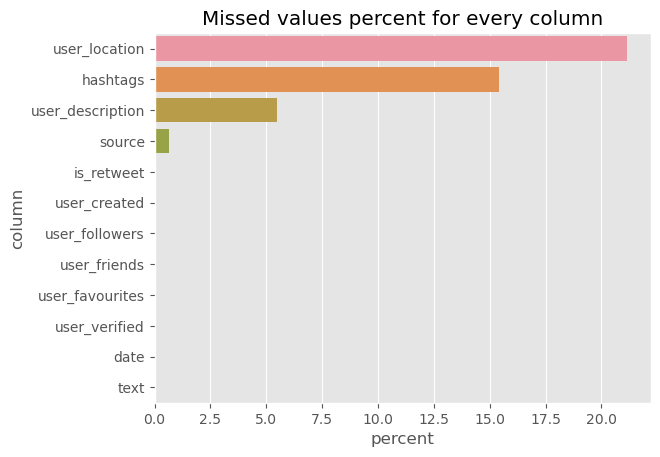

In [7]:
missed = pd.DataFrame()
missed['column'] = df.columns

missed['percent'] = [round(100* df[col].isnull().sum() / len(df), 2) for col in df.columns]
missed = missed.sort_values('percent',ascending=False)
missed = missed[missed['percent']>0]

fig = sns.barplot(
    x=missed['percent'], 
    y=missed["column"], 
    orientation='horizontal'
).set_title('Missed values percent for every column')

In [8]:
def unique_values(data):
    total = data.count()
    tt = pd.DataFrame(total)
    tt.columns = ['Total']
    uniques = []
    for col in data.columns:
        unique = data[col].nunique()
        uniques.append(unique)
    tt['Uniques'] = uniques
    tt['Percentage']=tt['Uniques']/tt['Total']
    return(np.transpose(tt))
unique_values(df)

,user_name,user_location,user_description,user_created,user_followers,user_friends,user_favourites,user_verified,date,text,hashtags,source,is_retweet
Total,399626.00000,315130.000000,377751.000000,399619.000000,399597.000000,399597.000000,399597.000000,399597.000000,399595.000000,399597.000000,337962.000000,397185.000000,399576.000000
Uniques,157948.00000,41218.000000,163464.000000,161181.000000,28677.000000,22341.000000,84744.000000,13.000000,389687.000000,399247.000000,144726.000000,968.000000,1.000000
Percentage,0.39524,0.130797,0.432729,0.403337,0.071765,0.055909,0.212074,0.000033,0.975205,0.999124,0.428232,0.002437,0.000003


In [9]:
def most_frequent_values(data):
    total = data.count()
    tt = pd.DataFrame(total)
    tt.columns = ['Total']
    items = []
    vals = []
    for col in data.columns:
        itm = data[col].value_counts().index[0]
        val = data[col].value_counts().values[0]
        items.append(itm)
        vals.append(val)
    tt['Most frequent item'] = items
    tt['Frequence'] = vals
    tt['Percent from total'] = np.round(vals / total * 100, 3)
    return(np.transpose(tt))
most_frequent_values(df)

,user_name,user_location,user_description,user_created,user_followers,user_friends,user_favourites,user_verified,date,text,hashtags,source,is_retweet
Total,399626,315130,377751,399619,399597,399597,399597,399597,399595,399597,337962,397185,399576
Most frequent item,VaxBLR,"Bengaluru, India",Hourly updates on FREE and PAID 18+ and 45+ va...,2021-06-21 08:44:34,40.0,0.0,0.0,False,20-08-2020 00:41,@mansukhmandviya Yes sir bcoz We #Pharmacist m...,['CovidVaccine'],Twitter Web App,False
Frequence,16821,17373,16821,16821,5183,11737,12508,295110,25,18,64911,118909,399576
Percent from total,4.209,5.513,4.453,4.209,1.297,2.937,3.13,73.852,0.006,0.005,19.207,29.938,100.0


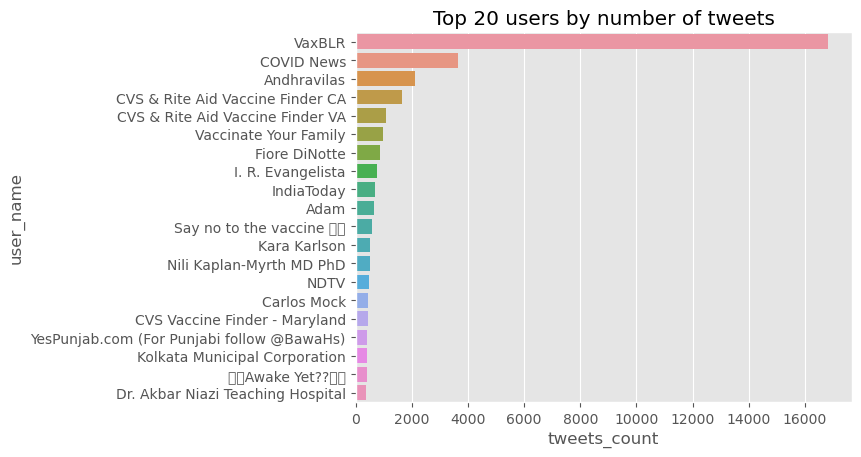

In [10]:
ds = df['user_name'].value_counts().reset_index()
ds.columns = ['user_name', 'tweets_count']
ds = ds.sort_values(['tweets_count'],ascending=False)
df = pd.merge(df, ds, on='user_name')

fig = sns.barplot( 
    x=ds.head(20)["tweets_count"], 
    y=ds.head(20)["user_name"], 
    orientation='horizontal'
).set_title('Top 20 users by number of tweets')


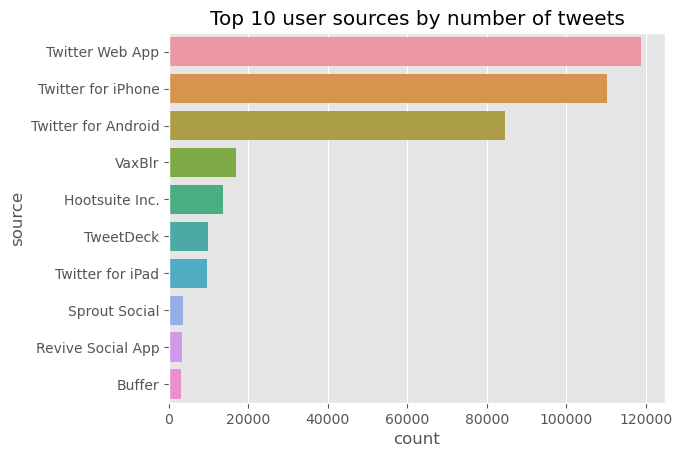

In [11]:
ds = df['source'].value_counts().reset_index()
ds.columns = ['source', 'count']
ds = ds.sort_values(['count'],ascending=False)

fig = sns.barplot(
    x=ds.head(10)["count"], 
    y=ds.head(10)["source"], 
    orientation='horizontal', 
    #title='Top 40 user sources by number of tweets', 
    #width=800, 
    #height=800
).set_title('Top 10 user sources by number of tweets')

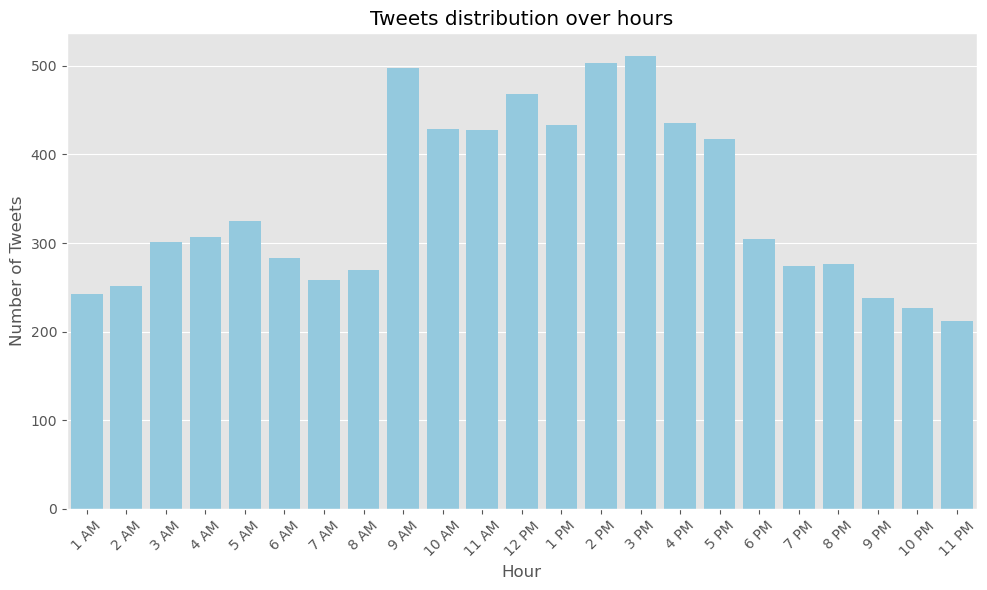

In [12]:



df['hour'] = pd.to_datetime(df['date'], errors='coerce').dt.hour
ds = df['hour'].value_counts().reset_index()
ds.columns = ['hour', 'count']
ds = ds.sort_values(by='hour')
hour_labels = {
    5: '5 AM', 6: '6 AM', 7: '7 AM', 8: '8 AM', 9: '9 AM', 10: '10 AM',
    11: '11 AM', 12: '12 PM', 13: '1 PM', 14: '2 PM', 15: '3 PM', 
    16: '4 PM', 17: '5 PM', 18: '6 PM', 19: '7 PM', 20: '8 PM', 
    21: '9 PM', 22: '10 PM', 23: '11 PM', 24: '12 AM', 1: '1 AM', 2:'2 AM', 3: '3 AM', 4: '4 AM'
}
ds['hour'] = ds['hour'].map(hour_labels)


# Plotting

plt.figure(figsize=(10, 6))
sns.barplot(x=ds["hour"], y=ds["count"], color='skyblue')
plt.title('Tweets distribution over hours')
plt.xlabel('Hour')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=45)  # Rotate x-labels for better readability
plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.show()




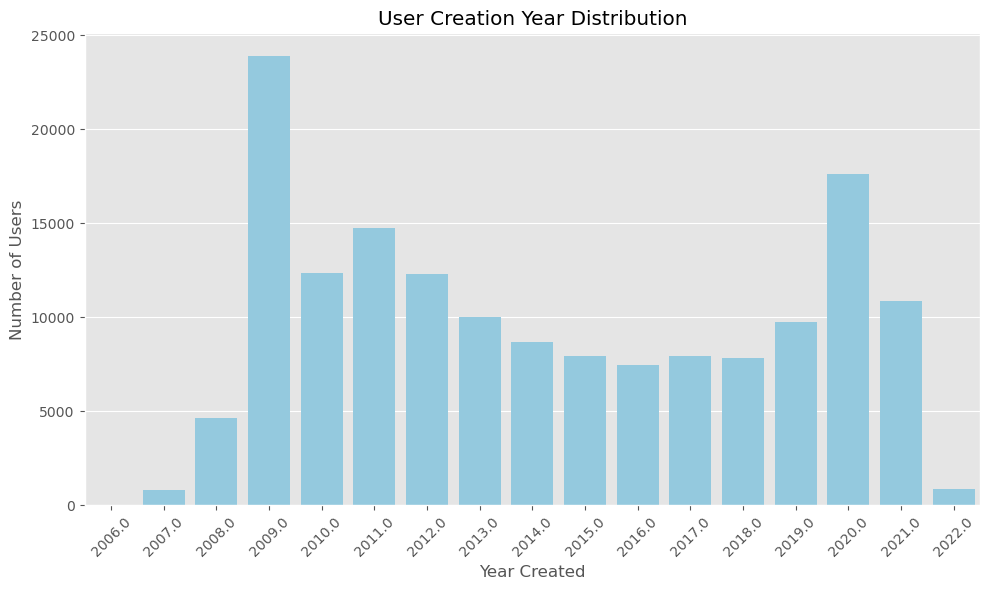

In [13]:
df['Timestamp'] = pd.to_datetime(df.user_created, format="%d-%m-%Y %H:%M", errors='coerce')
mask = df.Timestamp.isnull()
df.loc[mask, 'Timestamp'] = pd.to_datetime(df[mask]['user_created'], format='%Y-%m-%d %H:%M:%S',
                                             errors='coerce')
df['year_created'] = df['Timestamp'].dt.year
# Keep rows with 'year_created' greater than 1970
data = df.drop_duplicates(subset='user_name', keep="first")
data = data[data['year_created'] > 1970]
# Count the occurrences of each year
data = data['year_created'].value_counts().reset_index()
data.columns = ['year', 'number']
# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(x=data["year"], y=data["number"], color='skyblue')
plt.xlabel('Year Created')
plt.ylabel('Number of Users')
plt.title('User Creation Year Distribution')
# Adjust x-ticks for better spacing
plt.xticks(rotation=45)
plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.show()


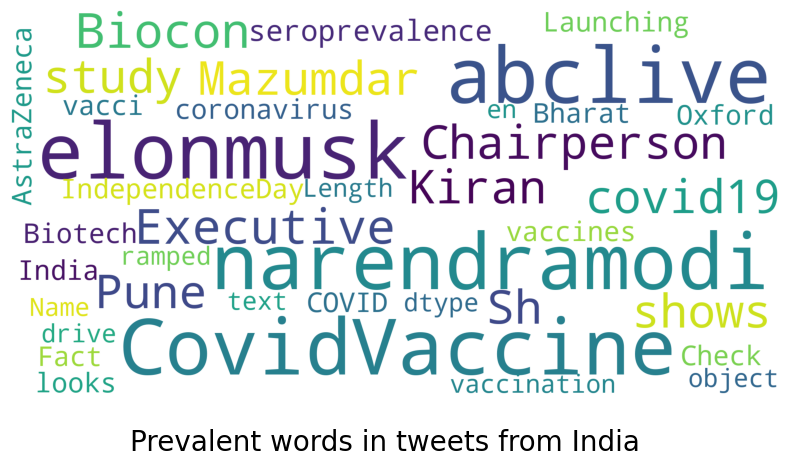

In [14]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
stopwords = set(STOPWORDS)
def show_wordcloud(data, title = None):
    wordcloud = WordCloud(
        background_color='white',
        stopwords=stopwords,
        max_words=50,
        max_font_size=40, 
        scale=5,
        random_state=1
    ).generate(str(data))

    fig = plt.figure(1, figsize=(10,10))
    plt.axis('off')
    if title: 
        fig.suptitle(title, fontsize=20)
        fig.subplots_adjust(top=2.3)
    plt.imshow(wordcloud)
    plt.show()
    
    
    
    
    
    
india_df = df.loc[df.user_location=="India"]
show_wordcloud(india_df['text'], title = 'Prevalent words in tweets from India')




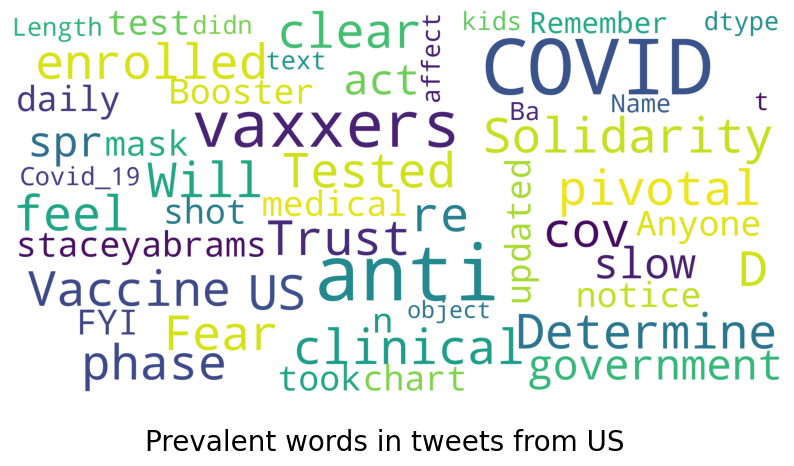

In [15]:






us_df = df.loc[df.user_location=="United States"]
show_wordcloud(us_df['text'], title = 'Prevalent words in tweets from US')




In [16]:
df.columns

Index(['user_name', 'user_location', 'user_description', 'user_created',
       'user_followers', 'user_friends', 'user_favourites', 'user_verified',
       'date', 'text', 'hashtags', 'source', 'is_retweet', 'tweets_count',
       'hour', 'Timestamp', 'year_created'],
      dtype='object')

In [17]:

text_df = df.drop(['user_name', 'user_location', 'user_description', 'user_created',
       'user_followers', 'user_friends', 'user_favourites', 'user_verified',
       'date', 'hashtags', 'source', 'is_retweet'],axis=1)
text_df.head()

,text,tweets_count,hour,Timestamp,year_created
0,Australia to Manufacture Covid-19 Vaccine and ...,2,12.0,2020-05-24 10:18:00,2020.0
1,Pfizer Inc said on Wednesday that final result...,2,NaN,2020-05-24 10:18:41,2020.0
2,#CoronavirusVaccine #CoronaVaccine #CovidVacci...,1,12.0,2020-08-14 16:42:00,2020.0
3,Deaths due to COVID-19 in Affected Countries\n...,1,12.0,2017-12-14 07:07:00,2017.0
4,@Team_Subhashree @subhashreesotwe @iamrajchoco...,4,12.0,2019-09-18 11:01:00,2019.0


In [18]:
print(text_df['text'].iloc[0],"\n")
print(text_df['text'].iloc[1],"\n")
print(text_df['text'].iloc[2],"\n")
print(text_df['text'].iloc[3],"\n")
print(text_df['text'].iloc[4],"\n")

Australia to Manufacture Covid-19 Vaccine and give it to the Citizens for free of cost: AFP quotes Prime Minister
#CovidVaccine 

Pfizer Inc said on Wednesday that final results from the late-stage trial of its #CovidVaccine show it was 95% effe… https://t.co/25RpCIFPqU 

#CoronavirusVaccine #CoronaVaccine #CovidVaccine Australia is doing very good https://t.co/kBT7l6pArY 

Deaths due to COVID-19 in Affected Countries
Read More: https://t.co/V8Y3Stu0UW
@r_piryani @shitalbhandary… https://t.co/6jpMxX2KtI 

@Team_Subhashree @subhashreesotwe @iamrajchoco Stay safe @subhashreesotwe di &amp; @iamrajchoco da ❤️❤️… https://t.co/ayhoaQm0Ls 



In [19]:

text_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399626 entries, 0 to 399625
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   text          399578 non-null  object        
 1   tweets_count  399626 non-null  int64         
 2   hour          8112 non-null    float64       
 3   Timestamp     399569 non-null  datetime64[ns]
 4   year_created  399569 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(1)
memory usage: 15.2+ MB


In [20]:




simple_text='This isn\'t a real text, this is an example text...Notice this contains punctuation!!'







In [21]:





import pandas as pd
import nltk
import re


tokenizer = nltk.tokenize.RegexpTokenizer('[a-zA-Z0-9\']+')
tokenized_document = tokenizer.tokenize(simple_text)
print(tokenized_document)









['This', "isn't", 'a', 'real', 'text', 'this', 'is', 'an', 'example', 'text', 'Notice', 'this', 'contains', 'punctuation']


In [22]:

stop_words = nltk.corpus.stopwords.words('english')
print(stop_words)

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

In [23]:


#remove stopwords
cleaned_tokens = []
for word in tokenized_document:
    word = word.lower()
    if word not in stop_words:
        cleaned_tokens.append(word)
print(cleaned_tokens)    




['real', 'text', 'example', 'text', 'notice', 'contains', 'punctuation']


In [24]:
# we can also remove stopwords using list comprehension
cleaned_tokens = [word.lower() for word in tokenized_document if word.lower() not in stop_words]
print(cleaned_tokens)



['real', 'text', 'example', 'text', 'notice', 'contains', 'punctuation']


In [25]:




# explore lemmatization vs stemming
lemmatizer = nltk.stem.WordNetLemmatizer()
stemmer = nltk.stem.PorterStemmer()

words = ['cacti','sings','hopped','rocks','better','easily']
pos = ['n','v','v','n','a','r']
lemmatized_words = [lemmatizer.lemmatize(words[i], pos=pos[i]) for i in range(6)]
stemmed_words = [stemmer.stem(word) for word in words]

print(" Lemmatized words: ", lemmatized_words)
print("Stemmed words: ", stemmed_words)



 Lemmatized words:  ['cactus', 'sing', 'hop', 'rock', 'good', 'easily']
Stemmed words:  ['cacti', 'sing', 'hop', 'rock', 'better', 'easili']


In [26]:



from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
# Create a stemming object
stemmer = PorterStemmer()
cleaned_tokens = [word.lower() for word in tokenized_document if word.lower() not in stop_words]
print(cleaned_tokens)
# Perform stemming on the tokens
stemmed_text = [stemmer.stem(word) for word in cleaned_tokens]
print(stemmed_text)




['real', 'text', 'example', 'text', 'notice', 'contains', 'punctuation']
['real', 'text', 'exampl', 'text', 'notic', 'contain', 'punctuat']


In [27]:
import pandas as pd
import nltk
import re
# Tokenization and Stopword Removal
tokenizer = nltk.tokenize.RegexpTokenizer('[a-zA-Z0-9\']+')
stop_words = set(nltk.corpus.stopwords.words('english'))
# Stemmer
stemmer = nltk.stem.PorterStemmer()
def data_processing(text):
    if not isinstance(text, str):
        text = str(text)  # Convert to string if it's not already one
    text = text.lower()
    text = re.sub(r'https?\S+|www\S+', '', text, flags=re.MULTILINE)  # Remove URLs
    text = re.sub(r'@\w+|#', '', text)  # Remove mentions and hashtags
    text = re.sub(r'[^\w\s]', '', text)  # Remove punctuation
    return text
def stemming(text):
    # Tokenize
    tokenized_document = tokenizer.tokenize(text)
    # Remove stopwords
    cleaned_tokens = [word.lower() for word in tokenized_document if word.lower() not in stop_words]
    # Stemming
    stemmed_text = [stemmer.stem(word) for word in cleaned_tokens]
    return ' '.join(stemmed_text)
# Assuming 'text_df' is your DataFrame with the 'text' column
text_df['text'] = text_df['text'].apply(data_processing)
text_df = text_df.drop_duplicates('text')
text_df['text'] = text_df['text'].apply(lambda x: stemming(x))

In [28]:
text_df.head()

,text,tweets_count,hour,Timestamp,year_created
0,australia manufactur covid19 vaccin give citiz...,2,12.0,2020-05-24 10:18:00,2020.0
1,pfizer inc said wednesday final result latesta...,2,NaN,2020-05-24 10:18:41,2020.0
2,coronavirusvaccin coronavaccin covidvaccin aus...,1,12.0,2020-08-14 16:42:00,2020.0
3,death due covid19 affect countri read,1,12.0,2017-12-14 07:07:00,2017.0
4,stay safe di amp da,4,12.0,2019-09-18 11:01:00,2019.0


In [29]:
print(text_df['text'].iloc[0],"\n")
print(text_df['text'].iloc[1],"\n")
print(text_df['text'].iloc[2],"\n")
print(text_df['text'].iloc[3],"\n")
print(text_df['text'].iloc[4],"\n")

australia manufactur covid19 vaccin give citizen free cost afp quot prime minist covidvaccin 

pfizer inc said wednesday final result latestag trial covidvaccin show 95 eff 

coronavirusvaccin coronavaccin covidvaccin australia good 

death due covid19 affect countri read 

stay safe di amp da 



In [30]:
text_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 375193 entries, 0 to 399625
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   text          375193 non-null  object        
 1   tweets_count  375193 non-null  int64         
 2   hour          7691 non-null    float64       
 3   Timestamp     375188 non-null  datetime64[ns]
 4   year_created  375188 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(1)
memory usage: 17.2+ MB


In [31]:
#Sentiment analysis 

def polarity(text):
    return TextBlob(text).sentiment.polarity
text_df['polarity'] = text_df['text'].apply(polarity)
text_df.head(5)


,text,tweets_count,hour,Timestamp,year_created,polarity
0,australia manufactur covid19 vaccin give citiz...,2,12.0,2020-05-24 10:18:00,2020.0,0.400
1,pfizer inc said wednesday final result latesta...,2,NaN,2020-05-24 10:18:41,2020.0,0.000
2,coronavirusvaccin coronavaccin covidvaccin aus...,1,12.0,2020-08-14 16:42:00,2020.0,0.700
3,death due covid19 affect countri read,1,12.0,2017-12-14 07:07:00,2017.0,-0.125
4,stay safe di amp da,4,12.0,2019-09-18 11:01:00,2019.0,0.500


In [32]:

def sentiment(label):
    if label <0:
        return "Negative"
    elif label ==0:
        return "Neutral"
    elif label > 0:
        return "Positive"
text_df['sentiment'] = text_df['polarity'].apply(sentiment)
text_df.head()



,text,tweets_count,hour,Timestamp,year_created,polarity,sentiment
0,australia manufactur covid19 vaccin give citiz...,2,12.0,2020-05-24 10:18:00,2020.0,0.400,Positive
1,pfizer inc said wednesday final result latesta...,2,NaN,2020-05-24 10:18:41,2020.0,0.000,Neutral
2,coronavirusvaccin coronavaccin covidvaccin aus...,1,12.0,2020-08-14 16:42:00,2020.0,0.700,Positive
3,death due covid19 affect countri read,1,12.0,2017-12-14 07:07:00,2017.0,-0.125,Negative
4,stay safe di amp da,4,12.0,2019-09-18 11:01:00,2019.0,0.500,Positive


<Axes: xlabel='sentiment', ylabel='count'>

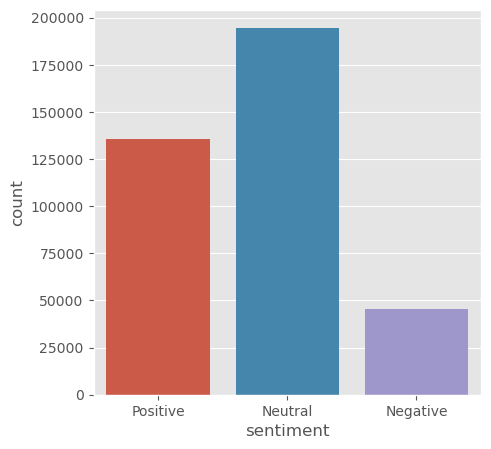

In [33]:



fig = plt.figure(figsize=(5,5))
sns.countplot(x='sentiment', data = text_df)






Text(0.5, 1.0, 'Distribution of sentiments')

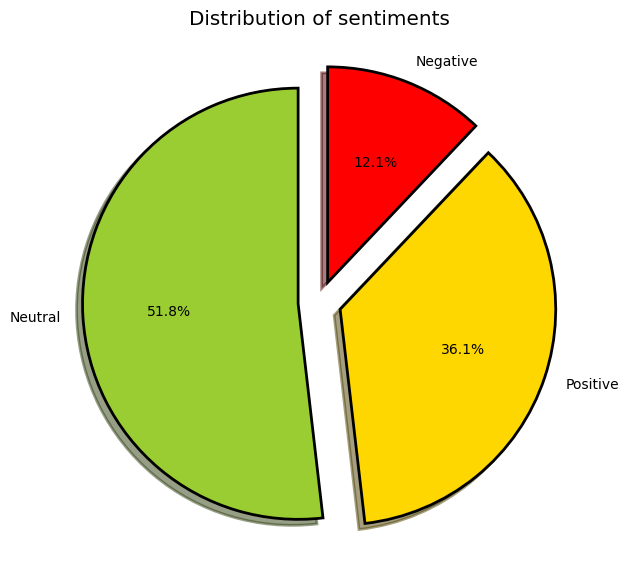

In [34]:
fig = plt.figure(figsize=(7,7))
colors = ("yellowgreen", "gold", "red")
wp = {'linewidth':2, 'edgecolor':"black"}
tags = text_df["sentiment"].value_counts()
explode = (0.1,0.1,0.1)
tags.plot(kind='pie', autopct='%1.1f%%', shadow=True, colors = colors,
         startangle=90, wedgeprops = wp, explode =explode, label='')
plt.title('Distribution of sentiments')

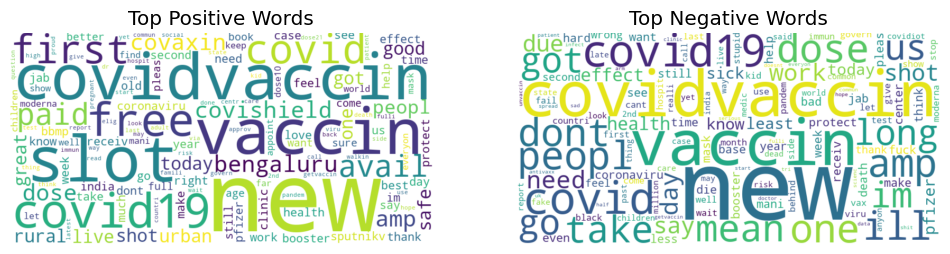

In [35]:
# Import Counter module to count word frequency
from collections import Counter
# Separate text data into positive and negative sentiments
positive_texts = text_df[text_df['sentiment'] == 'Positive']['text']
negative_texts = text_df[text_df['sentiment'] == 'Negative']['text']
# Join all the positive and negative texts into single strings
positive_text = ' '.join(positive_texts)
negative_text = ' '.join(negative_texts)
# Count word frequency for positive and negative texts
positive_word_freq = Counter(positive_text.split())
negative_word_freq = Counter(negative_text.split())
# Get top 100 to 150 words for positive and negative sentiments
top_positive_words = [word for word, _ in positive_word_freq.most_common(150)]
top_negative_words = [word for word, _ in negative_word_freq.most_common(150)]
# Join top positive and negative words into single strings
top_positive_text = ' '.join(top_positive_words)
top_negative_text = ' '.join(top_negative_words)
# Generate word clouds for top positive and negative words
top_positive_wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=150).generate(top_positive_text)
top_negative_wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=150).generate(top_negative_text)

# Plot the word clouds
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(top_positive_wordcloud, interpolation='bilinear')
plt.title('Top Positive Words')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(top_negative_wordcloud, interpolation='bilinear')
plt.title('Top Negative Words')
plt.axis('off')
plt.show()

In [36]:
def remove_tag(string):
    text=re.sub('<.*?>','',string)
    return text
def remove_mention(text):
    line=re.sub(r'@\w+','',text)
    return line
def remove_hash(text):
    line=re.sub(r'#\w+','',text)
    return line
def remove_newline(string):
    text=re.sub('\n','',string)
    return text
def remove_url(string): 
    text = re.sub('http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+','',string)
    return text
def remove_number(text):
    line=re.sub(r'[0-9]+','',text)
    return line
def remove_punct(text):
    line = re.sub(r'[!"\$%&\'()*+,\-.\/:;=#@?\[\\\]^_`{|}~]*','',text)
    return line
def text_strip(string):
    line=re.sub('\s{2,}', ' ', string.strip())
    return line
def remove_thi_amp_ha_words(string):
    line=re.sub(r'\bamp\b|\bthi\b|\bha\b',' ',string)
    return line
df['refine_text']=df['text'].str.lower()
df['refine_text']=df['refine_text'].apply(lambda x:remove_tag(str(x)))
df['refine_text']=df['refine_text'].apply(lambda x:remove_mention(str(x)))
df['refine_text']=df['refine_text'].apply(lambda x:remove_hash(str(x)))
df['refine_text']=df['refine_text'].apply(lambda x:remove_newline(x))
df['refine_text']=df['refine_text'].apply(lambda x:remove_url(x))
df['refine_text']=df['refine_text'].apply(lambda x:remove_number(x))
df['refine_text']=df['refine_text'].apply(lambda x:remove_punct(x))
df['refine_text']=df['refine_text'].apply(lambda x:remove_thi_amp_ha_words(x))
df['refine_text']=df['refine_text'].apply(lambda x:text_strip(x))
df['text_length']=df['refine_text'].str.split().map(lambda x: len(x))

In [37]:
import plotly.graph_objects as go

fig = go.Figure(data=go.Violin(y=df['text_length'], box_visible=True, line_color='black',
                               meanline_visible=True, fillcolor='royalblue', opacity=0.6,
                               x0='Tweet Text Length'))

fig.update_layout(yaxis_zeroline=False,title="Distribution of Text length",template='ggplot2')
fig.show()

In [38]:
from plotly.subplots import make_subplots

def ngram_df(corpus,nrange,n=None):
    vec = CountVectorizer(stop_words = 'english',ngram_range=nrange).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0) 
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq =sorted(words_freq, key = lambda x: x[1], reverse=True)
    total_list=words_freq[:n]
    df=pd.DataFrame(total_list,columns=['text','count'])
    return df
unigram_df=ngram_df(df['refine_text'],(1,1),20)
bigram_df=ngram_df(df['refine_text'],(2,2),20)
trigram_df=ngram_df(df['refine_text'],(3,3),20)

fig = make_subplots(
    rows=3, cols=1,subplot_titles=("Unigram","Bigram",'Trigram'),
    specs=[[{"type": "scatter"}],
           [{"type": "scatter"}],
           [{"type": "scatter"}]
          ])

fig.add_trace(go.Bar(
    y=unigram_df['text'][::-1],
    x=unigram_df['count'][::-1],
    marker={'color': "blue"},  
    text=unigram_df['count'],
    textposition = "outside",
    orientation="h",
    name="Months",
),row=1,col=1)

fig.add_trace(go.Bar(
    y=bigram_df['text'][::-1],
    x=bigram_df['count'][::-1],
    marker={'color': "blue"},  
    text=bigram_df['count'],
     name="Days",
    textposition = "outside",
    orientation="h",
),row=2,col=1)

fig.add_trace(go.Bar(
    y=trigram_df['text'][::-1],
    x=trigram_df['count'][::-1],
    marker={'color': "blue"},  
    text=trigram_df['count'],
     name="Days",
    orientation="h",
    textposition = "outside",
),row=3,col=1)

fig.update_xaxes(showline=True, linewidth=2, linecolor='black', mirror=True)
fig.update_yaxes(showline=True, linewidth=2, linecolor='black', mirror=True)
fig.update_layout(title_text='Top N Grams',xaxis_title=" ",yaxis_title=" ",
                  showlegend=False,title_x=0.5,height=1200,template="plotly_dark")
fig.show()

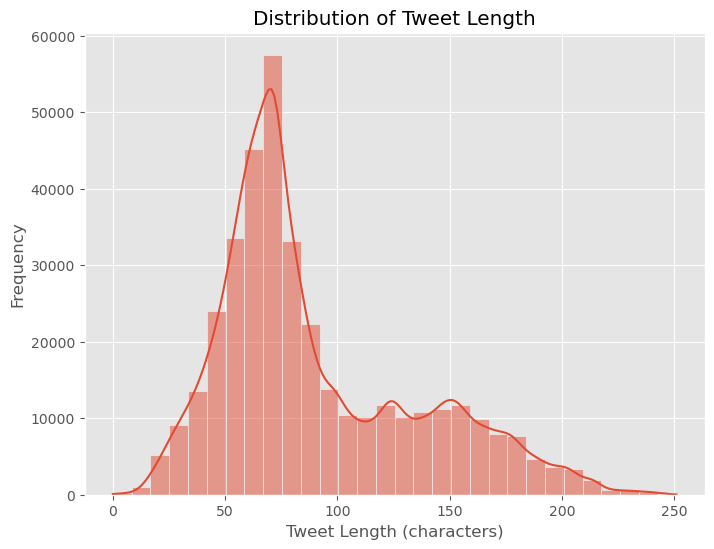

In [39]:
# Tweet Length Analysis
text_df['tweet_length'] = text_df['text'].apply(len)  # Compute tweet length
plt.figure(figsize=(8, 6))
sns.histplot(text_df['tweet_length'], bins=30, kde=True)
plt.title('Distribution of Tweet Length')
plt.xlabel('Tweet Length (characters)')
plt.ylabel('Frequency')
plt.show()

In [40]:


vect = CountVectorizer(ngram_range=(1,2)).fit(text_df['text'])
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd  # Make sure to import pandas module

# Instantiate CountVectorizer object with desired ngram_range
vect = CountVectorizer(ngram_range=(1, 2))

# Fit CountVectorizer to your text data and transform it (sparse matrix)
X_sparse = vect.fit_transform(text_df['text'])

# Work directly with the sparse matrix representation
print(X_sparse.shape)  # Print the shape of the sparse matrix



(375193, 1767123)


In [41]:

X = text_df['text']
Y = text_df['sentiment']

X = vect.transform(X)

x_train, x_test, y_train, y_test = train_test_split(X,Y, test_size=0.2, random_state=42)

print("Size of x_train:", (x_train.shape))
print("Size of y_train:", (y_train.shape))
print("Size of x_test:", (x_test.shape))
print("Size of y_test:", (y_test.shape))



Size of x_train: (300154, 1767123)
Size of y_train: (300154,)
Size of x_test: (75039, 1767123)
Size of y_test: (75039,)


<Axes: xlabel='sentiment', ylabel='count'>

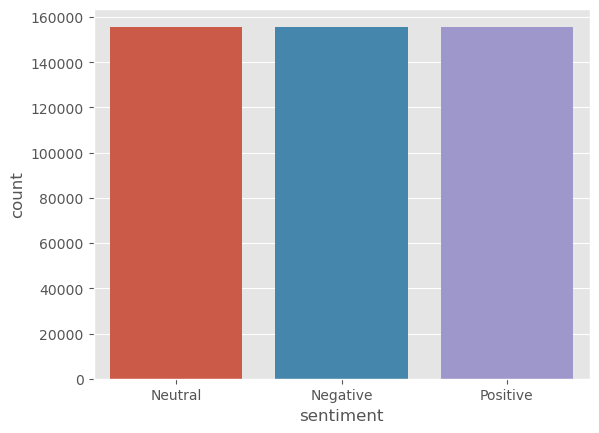

In [42]:



from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
x_train_balanced, y_train_balanced = smote.fit_resample(x_train, y_train)
sns.countplot(x=y_train_balanced)




In [43]:
from sklearn.feature_selection import VarianceThreshold
variance_selector = VarianceThreshold(threshold=0)
x_train_selected = variance_selector.fit_transform(x_train_balanced)
x_test_selected = variance_selector.transform(x_test)
print(f"{x_train_balanced.shape[1] - x_train_selected.shape[1]} features have been removed, {x_train_selected.shape[1]} features remain")

269551 features have been removed, 1497572 features remain


In [44]:
selected_features = variance_selector.get_support()
print("Size of boolean array:", selected_features.size)

Size of boolean array: 1767123


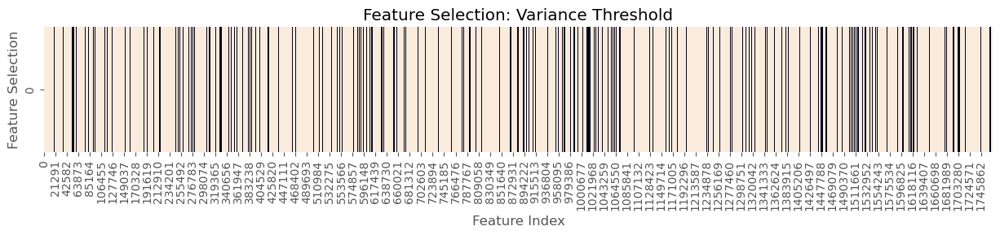

In [45]:
import seaborn as sns
import numpy as np
# Convert the boolean array to a one-dimensional numpy array
selected_features_array = np.array(selected_features)
# Reshape the array to have a single row
selected_features_row = selected_features_array.reshape(1, -1)
# Plot the boolean array as a heatmap
plt.figure(figsize=(15, 2))
sns.heatmap(selected_features_row, cmap='rocket', cbar=False)
plt.xlabel('Feature Index')
plt.ylabel('Feature Selection')
plt.title('Feature Selection: Variance Threshold')
plt.show()

In [46]:
from sklearn.feature_selection import SelectKBest, f_classif
selector = SelectKBest(f_classif, k=200)  # You can adjust the value of k as needed
x_train_selected = selector.fit_transform(x_train_balanced, y_train_balanced)
x_test_selected = selector.transform(x_test)

# Print the shape of the transformed training and testing data
print("Shape of x_train_selected:", x_train_selected.shape)
print("Shape of x_test_selected:", x_test_selected.shape)

selected_feature_indices = selector.get_support(indices=True)
print("Indices of selected features:", selected_feature_indices)

Shape of x_train_selected: (467097, 200)
Shape of x_test_selected: (75039, 200)
Indices of selected features: [    350     352     606     607     765     767    1105    1106    1234
    1235    1506    1507    1618    1620    1945    1946    2012    2013
    2266    2268    2718    2719    3099    3100    3212    3213    3655
    3656    3752    3753    4089    4091    6190    6196    7782    7792
    9950    9956   10781   10791   13089   13092   14317   14334   27005
   27010   27030   27032   32547   52755   65927   65956   66116   66152
  116282  122810  172303  202088  212493  218024  221140  221142  227131
  230953  230974  231951  233478  246760  310326  340292  357458  384424
  397506  397766  402005  405694  406069  411606  425031  439214  440104
  446709  446879  479537  535015  536516  538895  538896  539120  560425
  560429  560431  560437  566489  572547  581467  649358  651095  655286
  674945  677196  677614  677625  677707  678598  678623  678845  698748
  699735  7067

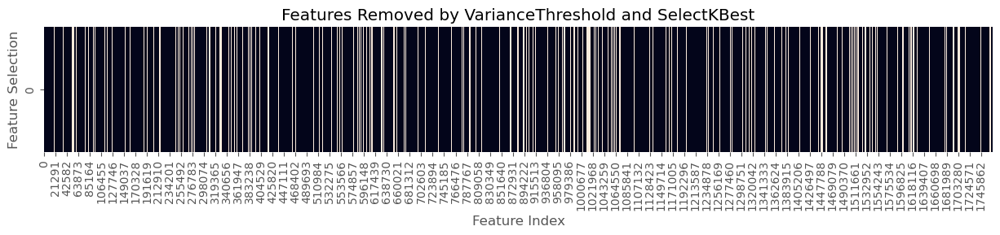

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
# Get the indices of features retained by VarianceThreshold
variance_threshold_indices = variance_selector.get_support(indices=True)
# Create a Boolean array indicating the features selected by SelectKBest
selected_features_boolean = np.zeros(x_train_balanced.shape[1], dtype=bool)
selected_features_boolean[selected_feature_indices] = True

# Create a Boolean array indicating features retained by VarianceThreshold
variance_threshold_boolean = np.zeros(x_train_balanced.shape[1], dtype=bool)
variance_threshold_boolean[variance_threshold_indices] = True

# Combine the two Boolean arrays to get features removed by both selectors
removed_features_boolean = ~(selected_features_boolean | variance_threshold_boolean)

# Reshape the array for visualization
removed_features_reshaped = removed_features_boolean.reshape(1, -1)

# Plot the heatmap of removed features
plt.figure(figsize=(15, 2))
sns.heatmap(removed_features_reshaped, cmap='rocket', cbar=False)
plt.xlabel('Feature Index')
plt.ylabel('Feature Selection')
plt.title('Features Removed by VarianceThreshold and SelectKBest')
plt.show()

In [48]:





from sklearn.preprocessing import StandardScaler
scaler = StandardScaler(with_mean=False)
x_train_scaled = scaler.fit_transform(x_train_selected)
x_test_scaled = scaler.transform(x_test_selected)









In [49]:
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix

In [50]:


from sklearn.linear_model import LogisticRegression

# Define the hyperparameters grid for tuning
param_grid = {
    'C': [0.1, 1, 10],
    'penalty': ['l1', 'l2']
}

# Initialize Logistic Regression classifier
logistic_regression = LogisticRegression(max_iter=1000, random_state=42)

# Perform GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(logistic_regression, param_grid, cv=5, scoring='accuracy')
grid_search.fit(x_train_scaled, y_train_balanced)

# Get the best hyperparameters from the grid search
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)





Best Hyperparameters: {'C': 10, 'penalty': 'l2'}


In [51]:
# Train the Logistic Regression classifier with the best hyperparameters
best_logistic_regression = LogisticRegression(**best_params, max_iter=1000, random_state=42)
best_logistic_regression.fit(x_train_scaled, y_train_balanced)

# Predict the sentiment labels for the test data
y_pred_logistic = best_logistic_regression.predict(x_test_scaled)

# Compute accuracy
accuracy = accuracy_score(y_test, y_pred_logistic)
print("Accuracy:", accuracy)

# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred_logistic)
print("Confusion Matrix:\n", conf_matrix)

# Generate classification report
print("Classification Report:\n", classification_report(y_test, y_pred_logistic))




Accuracy: 0.7858313676888018
Confusion Matrix:
 [[ 6648  1830   699]
 [ 9931 28779    88]
 [ 1336  2187 23541]]
Classification Report:
               precision    recall  f1-score   support

    Negative       0.37      0.72      0.49      9177
     Neutral       0.88      0.74      0.80     38798
    Positive       0.97      0.87      0.92     27064

    accuracy                           0.79     75039
   macro avg       0.74      0.78      0.74     75039
weighted avg       0.85      0.79      0.81     75039



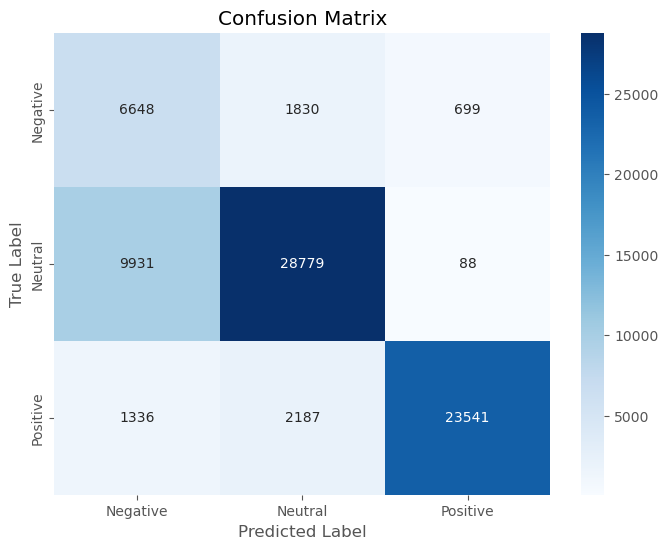

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predict the sentiment labels for the test data
y_pred_logistic = best_logistic_regression.predict(x_test_scaled)

# Compute confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred_logistic)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [53]:




from sklearn.naive_bayes import MultinomialNB

# Define the hyperparameters grid for tuning
param_grid = {
    'alpha': [0.1, 0.5, 1.0, 2.0]  # Smoothing parameter
}

# Initialize Multinomial Naive Bayes classifier
mnb_classifier = MultinomialNB()

# Perform GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(mnb_classifier, param_grid, cv=5, scoring='accuracy')
grid_search.fit(x_train_scaled, y_train_balanced)

# Get the best hyperparameters from the grid search
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)





Best Hyperparameters: {'alpha': 0.1}


In [54]:



# Train the Multinomial Naive Bayes classifier with the best hyperparameters
best_mnb_classifier = MultinomialNB(**best_params)
best_mnb_classifier.fit(x_train_scaled, y_train_balanced)

# Predict the sentiment labels for the test data
y_pred_mnb = best_mnb_classifier.predict(x_test_scaled)

# Compute accuracy
accuracy = accuracy_score(y_test, y_pred_mnb)
print("Accuracy:", accuracy)

# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred_mnb)
print("Confusion Matrix:\n", conf_matrix)

# Generate classification report
print("Classification Report:\n", classification_report(y_test, y_pred_mnb))


Accuracy: 0.7304601607164275
Confusion Matrix:
 [[ 6947  1787   443]
 [ 9952 28362   484]
 [ 4707  2853 19504]]
Classification Report:
               precision    recall  f1-score   support

    Negative       0.32      0.76      0.45      9177
     Neutral       0.86      0.73      0.79     38798
    Positive       0.95      0.72      0.82     27064

    accuracy                           0.73     75039
   macro avg       0.71      0.74      0.69     75039
weighted avg       0.83      0.73      0.76     75039



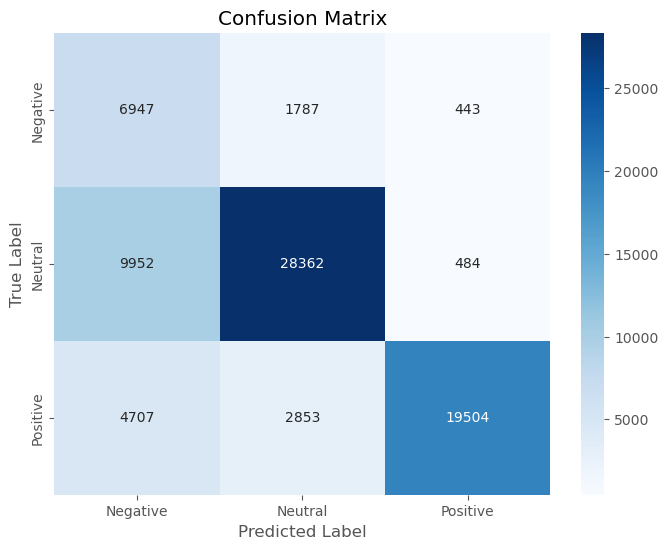

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predict the sentiment labels for the test data
y_pred_mnb = best_mnb_classifier.predict(x_test_scaled)

# Compute confusion matrix
conf_matrix_mnb = confusion_matrix(y_test, y_pred_mnb)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_mnb, annot=True, fmt="d", cmap="Blues", 
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()
